# Fetal Head Segmentation and Head Circumference Measurement (HC18)

Fine-tunes a pretrained U-Net to segment the fetal head in 2D ultrasound images, then measures the head circumference (HC) in mm from the predicted mask.

**Test results:** Dice 0.979, IoU 0.959, HC error 1.65 mm mean (1.23 mm median), 83% of cases within 3 mm.

The full write-up (method, failure analysis, limitations) is in the README. This notebook runs end to end on a free Colab T4 GPU.

## 1. Setup
Mount Google Drive so the data, split files and checkpoints survive a Colab disconnect.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
PROJ = '/content/drive/MyDrive/hc18'
os.makedirs(PROJ, exist_ok=True)

Mounted at /content/drive
Mounted at /content/drive


Install the two libraries Colab doesn't have and check that the GPU is available.

In [ ]:
!pip install -q segmentation-models-pytorch albumentations
import torch; print(torch.cuda.is_available())  # should print True

True


## 2. Data
Download HC18 from Zenodo to Drive once, then unzip it to the local disk each session (reading many small files from Drive is slow).

In [ ]:
%cd {PROJ}
if not os.path.exists('training_set.zip'):
    !wget -q -O training_set.zip "https://zenodo.org/records/1327317/files/training_set.zip?download=1"
    !wget -q -O train.csv "https://zenodo.org/records/1327317/files/training_set_pixel_size_and_HC.csv?download=1"
!unzip -q -o training_set.zip -d /content/data
!ls /content/data | head

/content/drive/MyDrive/hc18
training_set


Quick check: 999 images, 999 annotation outlines, and a CSV with the pixel size and the sonographer's HC for each image.

In [ ]:
import pandas as pd, glob
IMG_DIR = '/content/data/training_set'
df = pd.read_csv(f'{PROJ}/train.csv')
print(df.columns.tolist()); print(df.head()); print(len(df))
print(len(glob.glob(f'{IMG_DIR}/*_Annotation.png')))

['filename', 'pixel size(mm)', 'head circumference (mm)']
     filename  pixel size(mm)  head circumference (mm)
0  000_HC.png        0.069136                    44.30
1  001_HC.png        0.089659                    56.81
2  002_HC.png        0.062033                    68.75
3  003_HC.png        0.091291                    69.00
4  004_HC.png        0.061240                    59.81
999
999


## 3. Outlines to filled masks
The annotations are outlines, some with small gaps, so I fit an ellipse to each one and fill it. To check this step, the perimeter of each fitted ellipse is converted to mm and compared with the sonographer's HC value (mean difference 0.01 mm).

In [ ]:
import cv2, numpy as np
MASK_DIR = '/content/data/masks'; os.makedirs(MASK_DIR, exist_ok=True)
FN, PIX, HC = df.columns[0], df.columns[1], df.columns[2]
perims = []
for name in df[FN]:
    ann = cv2.imread(f"{IMG_DIR}/{name.replace('.png','_Annotation.png')}", 0)
    ys, xs = np.nonzero(ann)
    ell = cv2.fitEllipse(np.stack([xs, ys], 1).astype(np.float32))
    mask = np.zeros_like(ann); cv2.ellipse(mask, ell, 255, -1)
    cv2.imwrite(f'{MASK_DIR}/{name}', mask)
    a, b = ell[1][0]/2, ell[1][1]/2
    perims.append(np.pi*(3*(a+b) - np.sqrt((3*a+b)*(a+3*b))))  # Ramanujan
df['hc_fit_mm'] = np.array(perims) * df[PIX]
print((df['hc_fit_mm'] - df[HC]).abs().describe())

count    999.000000
mean       0.008851
std        0.007845
min        0.000003
25%        0.003452
50%        0.007178
75%        0.011988
max        0.070149
dtype: float64


## 4. Train / validation / test split
70 / 15 / 15, grouped by the number in the filename. Images like `023_HC.png` and `023_2HC.png` are likely repeat scans of the same fetus, so they always stay in the same split. The split is saved to Drive so it stays the same across sessions.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
df['subject'] = df[FN].str.split('_').str[0]
g = GroupShuffleSplit(1, test_size=0.15, random_state=42)
tv, te = next(g.split(df, groups=df['subject']))
trainval, test = df.iloc[tv], df.iloc[te]
g2 = GroupShuffleSplit(1, test_size=0.176, random_state=42)  # 0.176 of 85% ≈ 15%
tr, va = next(g2.split(trainval, groups=trainval['subject']))
train, val = trainval.iloc[tr], trainval.iloc[va]
for n, d in [('train', train), ('val', val), ('test', test)]:
    d.to_csv(f'{PROJ}/split_{n}.csv', index=False); print(n, len(d))

train 703
val 141
test 155


## 5. Dataset and DataLoaders
Images are resized to 384×256 and the grayscale channel is copied to 3 channels for the ImageNet encoder. Training images get flips, rotations and brightness/contrast changes.

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
H, W = 256, 384
train_tf = A.Compose([A.Resize(H, W), A.HorizontalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5, border_mode=cv2.BORDER_CONSTANT),
    A.RandomBrightnessContrast(p=0.3), A.Normalize(), ToTensorV2()])
eval_tf = A.Compose([A.Resize(H, W), A.Normalize(), ToTensorV2()])

class HC18(Dataset):
    def __init__(self, frame, tf):
        self.names = frame[FN].tolist(); self.tf = tf
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        img = np.stack([cv2.imread(f'{IMG_DIR}/{n}', 0)]*3, -1)
        mask = (cv2.imread(f'{MASK_DIR}/{n}', 0) > 127).astype(np.float32)
        out = self.tf(image=img, mask=mask)
        return out['image'], out['mask'].unsqueeze(0)

train_dl = DataLoader(HC18(train, train_tf), batch_size=8, shuffle=True, num_workers=2)
val_dl   = DataLoader(HC18(val, eval_tf),   batch_size=8, num_workers=2)
test_dl  = DataLoader(HC18(test, eval_tf),  batch_size=8, num_workers=2)

Sanity check: the red mask outlines should sit on the skull, including on flipped and rotated images. This confirms the images and masks are transformed together.

torch.Size([8, 3, 256, 384]) torch.Size([8, 1, 256, 384]) 0.3525632321834564


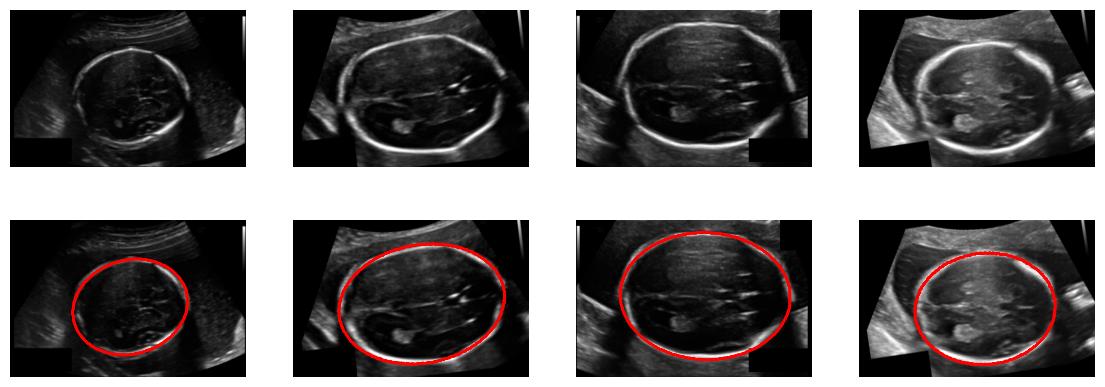

In [ ]:
import matplotlib.pyplot as plt
x, y = next(iter(train_dl))
print(x.shape, y.shape, y.mean().item())  # [8,3,256,384] [8,1,256,384]
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
for i in range(4):
    ax[0,i].imshow(x[i,0], cmap='gray'); ax[1,i].imshow(x[i,0], cmap='gray')
    ax[1,i].contour(y[i,0], colors='r'); ax[0,i].axis('off'); ax[1,i].axis('off')
plt.show()

## 6. Model
U-Net with a ResNet34 encoder pretrained on ImageNet.

In [ ]:
import segmentation_models_pytorch as smp
import torch.nn as nn
device = 'cuda'
model = smp.Unet(encoder_name='resnet34', encoder_weights='imagenet',
                 in_channels=3, classes=1).to(device)

Loss is Dice + binary cross-entropy. The metric function returns Dice and IoU per image so the worst cases can be found later.

In [ ]:
dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)
bce = nn.BCEWithLogitsLoss()
def loss_fn(logits, y): return dice_loss(logits, y) + bce(logits, y)

def dice_iou(logits, y, thr=0.5):
    p = (torch.sigmoid(logits) > thr).float()
    inter = (p*y).sum((1,2,3)); ps = p.sum((1,2,3)); ys = y.sum((1,2,3))
    dice = (2*inter + 1e-6) / (ps + ys + 1e-6)
    iou = (inter + 1e-6) / (ps + ys - inter + 1e-6)
    return dice, iou

## 7. Training
AdamW with a cosine learning rate schedule and mixed precision.

In [ ]:
EPOCHS = 30
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')
CKPT = f'{PROJ}/checkpoints'; os.makedirs(CKPT, exist_ok=True)

Resume from the last checkpoint if one exists, so a Colab disconnect doesn't mean starting over.

In [ ]:
start_epoch, best_dice, history = 0, 0.0, []
if os.path.exists(f'{CKPT}/last.pt'):
    ck = torch.load(f'{CKPT}/last.pt', map_location=device)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start_epoch, best_dice, history = ck['epoch'] + 1, ck['best_dice'], ck['history']
    print(f'Resuming from epoch {start_epoch}, best val Dice {best_dice:.4f}')

Train for 30 epochs. `best.pt` keeps the epoch with the best validation Dice (epoch 17, val Dice 0.977), and `last.pt` is saved every epoch for resuming.

In [ ]:
import time
for epoch in range(start_epoch, EPOCHS):
    t0 = time.time(); model.train(); tr_loss = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.amp.autocast('cuda'):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tr_loss += loss.item() * len(x)
    sched.step()

    model.eval(); va_loss, dices, ious = 0, [], []
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            va_loss += loss_fn(logits, y).item() * len(x)
            d, i = dice_iou(logits.float(), y); dices.append(d); ious.append(i)
    vd, vi = torch.cat(dices).mean().item(), torch.cat(ious).mean().item()
    tl, vl = tr_loss/len(train_dl.dataset), va_loss/len(val_dl.dataset)
    history.append(dict(epoch=epoch, train_loss=tl, val_loss=vl, val_dice=vd, val_iou=vi))
    if vd > best_dice:
        best_dice = vd; torch.save(model.state_dict(), f'{CKPT}/best.pt')
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), epoch=epoch, best_dice=best_dice,
                    history=history), f'{CKPT}/last.pt')
    print(f'ep {epoch:2d} | train {tl:.4f} | val {vl:.4f} | Dice {vd:.4f} | IoU {vi:.4f} | {time.time()-t0:.0f}s')

ep  0 | train 0.6208 | val 0.4203 | Dice 0.9594 | IoU 0.9246 | 18s
ep  1 | train 0.2979 | val 0.2106 | Dice 0.9534 | IoU 0.9188 | 15s
ep  2 | train 0.1603 | val 0.1516 | Dice 0.9595 | IoU 0.9257 | 16s
ep  3 | train 0.1209 | val 0.1202 | Dice 0.9618 | IoU 0.9300 | 15s
ep  4 | train 0.1121 | val 0.1036 | Dice 0.9656 | IoU 0.9346 | 15s
ep  5 | train 0.0898 | val 0.0880 | Dice 0.9696 | IoU 0.9424 | 18s
ep  6 | train 0.0785 | val 0.0750 | Dice 0.9736 | IoU 0.9491 | 16s
ep  7 | train 0.0727 | val 0.0745 | Dice 0.9736 | IoU 0.9488 | 23s
ep  8 | train 0.0682 | val 0.0705 | Dice 0.9735 | IoU 0.9488 | 19s
ep  9 | train 0.0656 | val 0.0673 | Dice 0.9748 | IoU 0.9513 | 20s
ep 10 | train 0.0637 | val 0.0653 | Dice 0.9751 | IoU 0.9519 | 22s
ep 11 | train 0.0627 | val 0.0653 | Dice 0.9754 | IoU 0.9521 | 22s
ep 12 | train 0.0603 | val 0.0643 | Dice 0.9750 | IoU 0.9516 | 23s
ep 13 | train 0.0580 | val 0.0639 | Dice 0.9755 | IoU 0.9524 | 22s
ep 14 | train 0.0562 | val 0.0639 | Dice 0.9753 | IoU 0.9524 |

Validation stops improving after about epoch 17 while training loss keeps falling: mild overfitting, handled by keeping the best checkpoint.

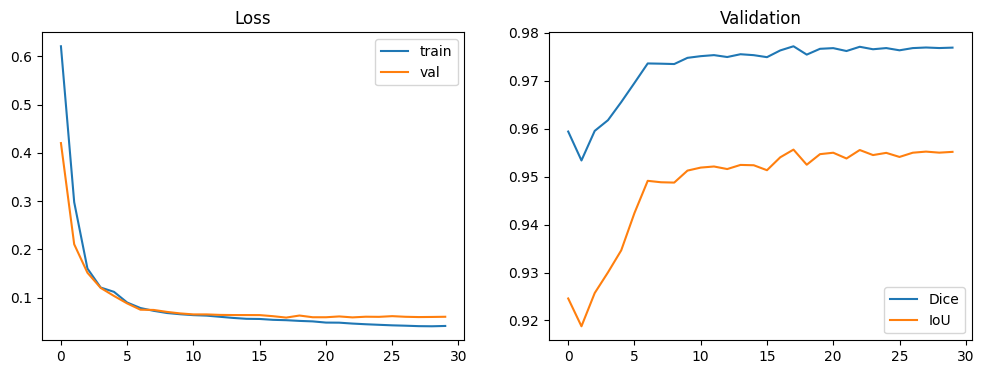

In [ ]:
h = pd.DataFrame(history); h.to_csv(f'{PROJ}/history.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h.epoch, h.val_dice, label='Dice'); ax[1].plot(h.epoch, h.val_iou, label='IoU')
ax[1].set_title('Validation'); ax[1].legend()
plt.savefig(f'{PROJ}/curves.png', dpi=120); plt.show()

## 8. Test evaluation
The test split is used once, with the best checkpoint.

In [ ]:
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=device)); model.eval()
names = test[FN].tolist()
probs, dices, ious = [], [], []
with torch.no_grad():
    for x, y in test_dl:
        logits = model(x.to(device)).float()
        d, i = dice_iou(logits, y.to(device))
        dices.append(d.cpu()); ious.append(i.cpu()); probs.append(torch.sigmoid(logits).cpu())
probs = torch.cat(probs)[:, 0].numpy()
res = test[[FN, PIX, HC]].reset_index(drop=True).copy()
res['dice'] = torch.cat(dices).numpy(); res['iou'] = torch.cat(ious).numpy()
print(res[['dice', 'iou']].describe())

             dice         iou
count  155.000000  155.000000
mean     0.978635    0.958484
std      0.013471    0.024450
min      0.861986    0.757448
25%      0.974605    0.950468
50%      0.981419    0.963515
75%      0.986621    0.973595
max      0.992489    0.985089


## 9. Head circumference in mm
Each prediction is resized to the original image size, the largest region is kept, an ellipse is fitted, and its perimeter is converted to mm using that image's pixel size.

In [ ]:
def hc_from_prob(prob, orig_hw, pix):
    p = cv2.resize(prob, (orig_hw[1], orig_hw[0]), interpolation=cv2.INTER_LINEAR)
    m = (p > 0.5).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts: return np.nan
    c = max(cnts, key=cv2.contourArea)
    if len(c) < 5: return np.nan
    _, (w, h), _ = cv2.fitEllipse(c)
    a, b = w/2, h/2
    return pix * np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))

res['hc_pred_mm'] = [hc_from_prob(probs[k], cv2.imread(f'{IMG_DIR}/{n}', 0).shape, res.loc[k, PIX])
                     for k, n in enumerate(names)]
res['hc_abs_err_mm'] = (res['hc_pred_mm'] - res[HC]).abs()
res['hc_rel_err_pct'] = 100 * res['hc_abs_err_mm'] / res[HC]
ref_err = (df.set_index(FN).loc[names, 'hc_fit_mm'] - df.set_index(FN).loc[names, HC]).abs()

print(f"Dice  {res.dice.mean():.4f} ± {res.dice.std():.4f}")
print(f"IoU   {res.iou.mean():.4f} ± {res.iou.std():.4f}")
print(f"HC abs error  mean {res.hc_abs_err_mm.mean():.2f} mm | median {res.hc_abs_err_mm.median():.2f} mm")
print(f"HC rel error  mean {res.hc_rel_err_pct.mean():.2f} %")
print(f"Within 3 mm: {(res.hc_abs_err_mm <= 3).mean()*100:.1f} % | failed fits: {res.hc_pred_mm.isna().sum()}")
print(f"Ellipse-fit error on true masks (noise floor): {ref_err.mean():.2f} mm")
res.to_csv(f'{PROJ}/test_results.csv', index=False)

Dice  0.9786 ± 0.0135
IoU   0.9585 ± 0.0244
HC abs error  mean 1.65 mm | median 1.23 mm
HC rel error  mean 1.07 %
Within 3 mm: 83.2 % | failed fits: 0
Ellipse-fit error on true masks (noise floor): 0.01 mm


## 10. Error vs head size
Absolute error grows with head size, while relative error is highest on small heads.

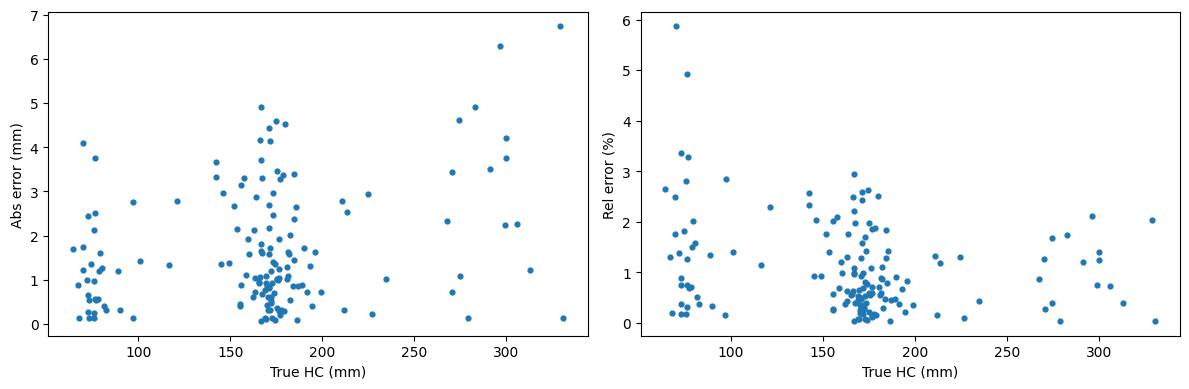

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(res[HC], res.hc_abs_err_mm, s=12); ax[0].set_xlabel('True HC (mm)'); ax[0].set_ylabel('Abs error (mm)')
ax[1].scatter(res[HC], res.hc_rel_err_pct, s=12); ax[1].set_xlabel('True HC (mm)'); ax[1].set_ylabel('Rel error (%)')
plt.tight_layout(); plt.savefig(f'{PROJ}/error_vs_size.png', dpi=120); plt.show()

## 11. Failure analysis
Worst 8 test cases by Dice. Green is the ground truth, red is the prediction.

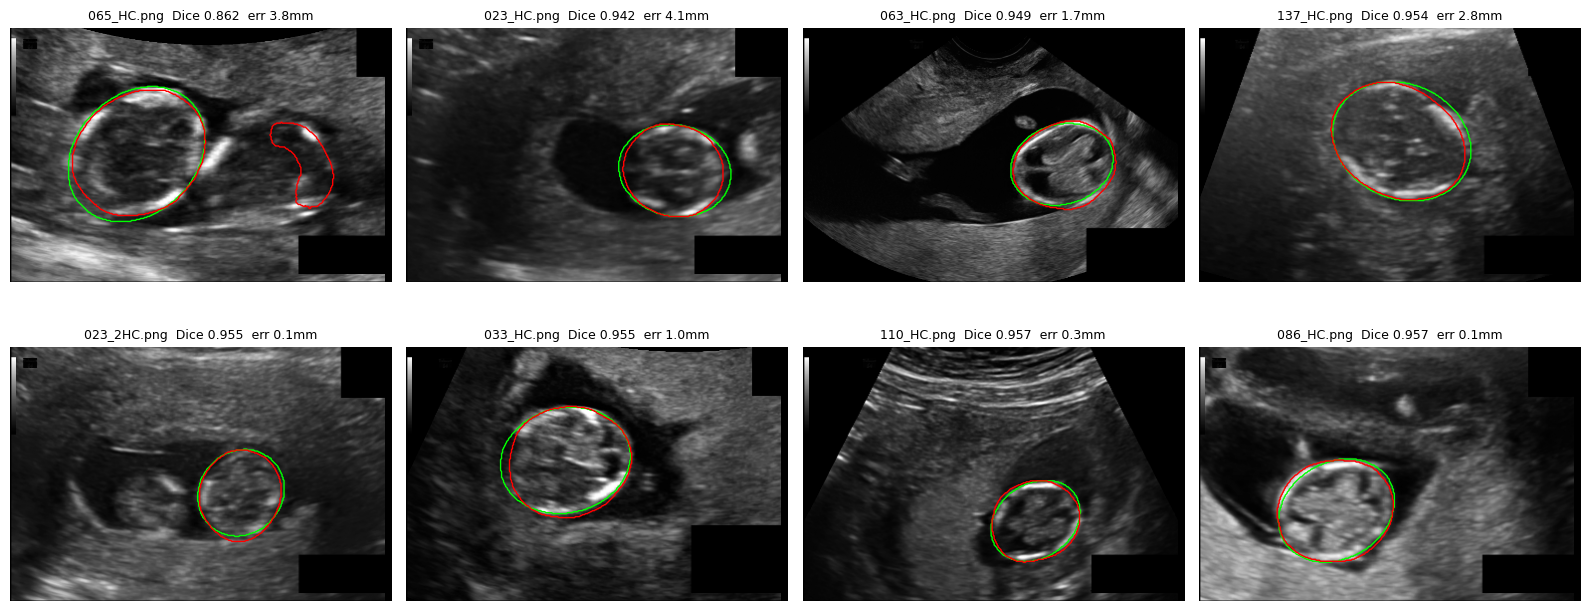

In [ ]:
worst = res.sort_values('dice').head(8)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, (k, r) in zip(ax.flat, worst.iterrows()):
    img = cv2.resize(cv2.imread(f'{IMG_DIR}/{r[FN]}', 0), (W, H))
    gt = cv2.resize(cv2.imread(f'{MASK_DIR}/{r[FN]}', 0), (W, H)) > 127
    a.imshow(img, cmap='gray'); a.contour(gt, colors='lime', linewidths=1)
    a.contour(probs[k] > 0.5, colors='red', linewidths=1)
    a.set_title(f"{r[FN]}  Dice {r.dice:.3f}  err {r.hc_abs_err_mm:.1f}mm", fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(f'{PROJ}/worst_by_dice.png', dpi=120); plt.show()

Worst 8 test cases by HC error in mm. These are different images from the Dice ranking: the segmentations look good, but the boundary drifts slightly where the skull edge is faint.

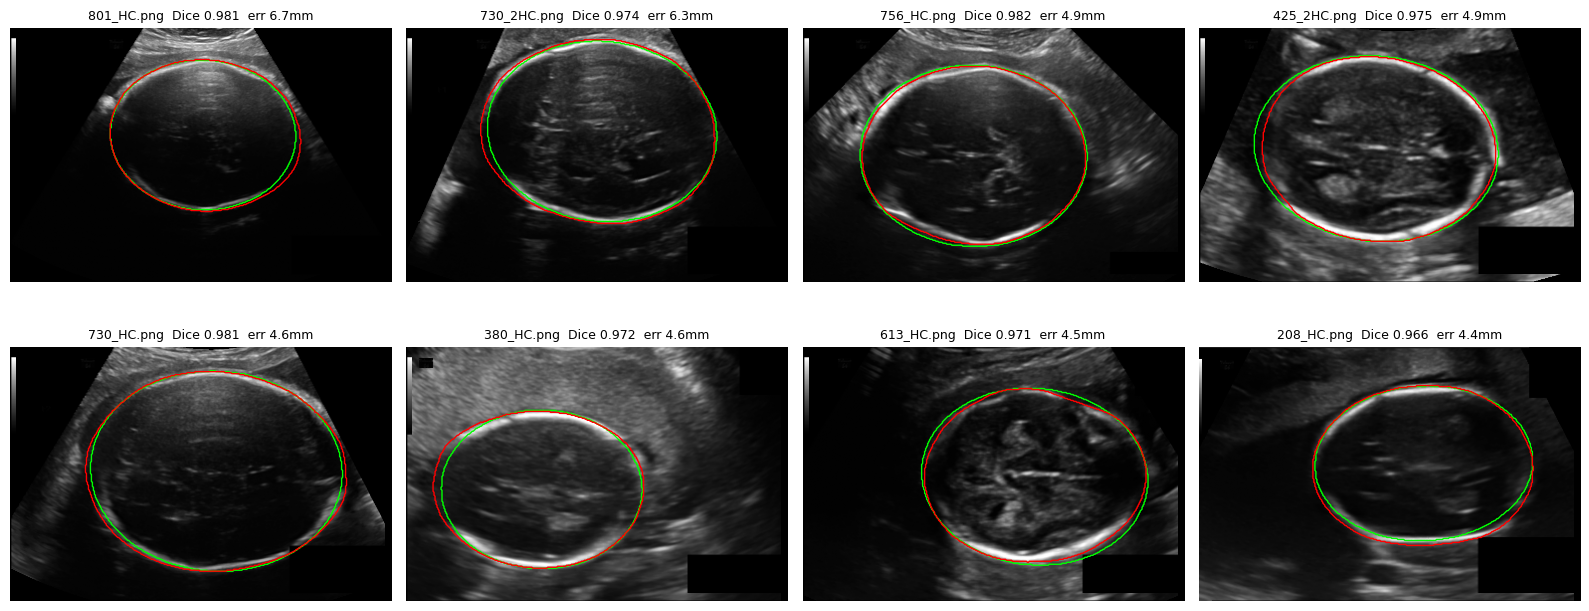

In [ ]:
worst = res.sort_values('hc_abs_err_mm', ascending=False).head(8)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, (k, r) in zip(ax.flat, worst.iterrows()):
    img = cv2.resize(cv2.imread(f'{IMG_DIR}/{r[FN]}', 0), (W, H))
    gt = cv2.resize(cv2.imread(f'{MASK_DIR}/{r[FN]}', 0), (W, H)) > 127
    a.imshow(img, cmap='gray'); a.contour(gt, colors='lime', linewidths=1)
    a.contour(probs[k] > 0.5, colors='red', linewidths=1)
    a.set_title(f"{r[FN]}  Dice {r.dice:.3f}  err {r.hc_abs_err_mm:.1f}mm", fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(f'{PROJ}/worst_by_hc_error.png', dpi=120); plt.show()

Larger heads were scanned at a coarser pixel size (correlation 0.80), which is why the same small pixel error costs more millimetres on them.

In [ ]:
print(res[[PIX, HC]].corr())

                         pixel size(mm)  head circumference (mm)
pixel size(mm)                 1.000000                 0.803851
head circumference (mm)        0.803851                 1.000000
